# CS 521 HW4, Problem 3: PPO on CartPole

Open this notebook in Google Colab. The CPU runtime is sufficient: a GPU does not make this notebook faster.

The notebook has a complete implementation of PPO for the CartPole-v1 environment.
In part (a) of Problem 3, you run it and examine two of its parts.
In Bonus Research Question 2, you change the algorithm to improve learning.
Do not change the environment, the training budget (`total_steps`) or the evaluation.

**Environment.** CartPole-v1 gives a reward of +1 for each step. An episode ends when the pole falls
(*termination*) or after 500 steps (*truncation*, a time limit). Thus the maximum return is 500.

In [1]:
# !pip install gymnasium   # Colab has gymnasium. Remove the comment if the import fails.
import copy
import time

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical

torch.set_num_threads(1)

CONFIG = dict(
    total_steps=200_000,   # training budget (environment steps). Do not change.
    num_envs=4,            # parallel environments
    num_steps=128,         # steps per environment for each rollout
    lr=2.5e-4,
    anneal_lr=True,        # decrease the learning rate linearly to 0
    gamma=0.99,
    gae_lambda=0.95,
    num_minibatches=4,
    update_epochs=4,
    clip_coef=0.2,
    ent_coef=0.01,
    vf_coef=0.5,
    max_grad_norm=0.5,
    norm_adv=True,         # normalize the advantages in each minibatch
)
SEEDS = [0, 1, 2, 3, 4]

# Environments

`Envs` runs `num_envs` copies of CartPole. When an episode ends, `step` resets that copy automatically.
For each copy, `step` returns:

* `obs`: the next observation. If the episode ended, this is the first observation of the new episode.
* `reward`, `terminated`, `truncated`.
* `final_obs`: the last observation of the episode that ended (`None` if the episode did not end).

`step` also records the return of each finished episode in `self.episodes` as `(global_step, return)`.

In [2]:
class Envs:
    def __init__(self, n, seed):
        self.envs = [gym.make("CartPole-v1") for _ in range(n)]
        self.obs = np.stack([e.reset(seed=seed + i)[0] for i, e in enumerate(self.envs)])
        for i, e in enumerate(self.envs):
            e.action_space.seed(seed + i)
        self.ep_return = np.zeros(n)
        self.global_step = 0
        self.episodes = []

    def step(self, actions):
        rewards, terms, truncs, final_obs = [], [], [], []
        for i, (e, a) in enumerate(zip(self.envs, actions)):
            o, r, term, trunc, _ = e.step(int(a))
            self.ep_return[i] += r
            fo = None
            if term or trunc:
                fo = o
                self.episodes.append((self.global_step + i + 1, self.ep_return[i]))
                self.ep_return[i] = 0
                o, _ = e.reset()
            self.obs[i] = o
            rewards.append(r); terms.append(term); truncs.append(trunc); final_obs.append(fo)
        self.global_step += len(self.envs)
        return self.obs.copy(), np.array(rewards), np.array(terms), np.array(truncs), final_obs

# Agent

The agent has two separate networks with 2 hidden layers of 64 neurons: the actor (policy) and the critic (value).

In [3]:
def layer_init(layer, std=np.sqrt(2), bias=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias)
    return layer


class Agent(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 1), std=1.0))
        self.actor = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, n_actions), std=0.01))

    def get_value(self, x):
        return self.critic(x).squeeze(-1)

    def get_action_and_value(self, x, action=None):
        dist = Categorical(logits=self.actor(x))
        if action is None:
            action = dist.sample()
        return action, dist.log_prob(action), dist.entropy(), self.get_value(x)

# PPO

`compute_gae` calculates the advantages with generalized advantage estimation (GAE).
`ppo_update` does `update_epochs` passes over the rollout with the clipped surrogate objective.
`train_ppo(seed, cfg)` trains one agent and returns the agent and the list of `(global_step, return)` of the
training episodes.

In [4]:
def compute_gae(rewards, values, dones, next_value, next_done, gamma, lam):
    # rewards, values, dones: (num_steps, num_envs). dones[t] = 1 if the episode ended at step t - 1,
    # thus obs[t] is the first observation of a new episode.
    T = len(rewards)
    adv = torch.zeros_like(rewards)
    last = 0
    for t in reversed(range(T)):
        not_done = 1.0 - (next_done if t == T - 1 else dones[t + 1])
        nv = next_value if t == T - 1 else values[t + 1]
        delta = rewards[t] + gamma * nv * not_done - values[t]
        last = delta + gamma * lam * not_done * last
        adv[t] = last
    return adv, adv + values


def ppo_update(agent, opt, b, cfg):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    stats = []
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = torch.max(-adv * ratio,
                                -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            opt.step()
            stats.append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
    return {"clip_frac": float(np.mean(stats))}


def train_ppo(seed, cfg=None, verbose=False):
    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4); actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N); rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v
            o, r, term, trunc, _ = envs.step(a.numpy())
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        stats = ppo_update(agent, opt, b, cfg)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  "
                  f"clip frac {stats['clip_frac']:.3f}")
    return agent, envs.episodes, time.time() - start

# Evaluation

`evaluate_policy` runs the greedy policy (the action with the highest probability) for 20 episodes with fixed seeds.
`summarize(runs)` gives these metrics for a list of runs (one run for each seed):

* `auc`: the mean of the learning curve over the training budget. The learning curve is the mean return of the last
  10 training episodes, at 100 equally spaced steps. A higher value means faster learning.
* `steps_to_475`: the first step where the mean return of the last 10 training episodes is at least 475.
  If a run does not get there, we use `total_steps`.
* `final`: the return of the greedy policy at the end of training.

`plot_curves` plots the mean learning curve over the seeds. Use these functions for all the numbers in your report.

In [5]:
@torch.no_grad()
def evaluate_policy(agent, episodes=20, seed=10_000):
    env = gym.make("CartPole-v1")
    total = 0.0
    for k in range(episodes):
        o, _ = env.reset(seed=seed + k)
        done = False
        while not done:
            a = agent.actor(torch.tensor(o, dtype=torch.float32)).argmax().item()
            o, r, term, trunc, _ = env.step(a)
            total += r
            done = term or trunc
    return total / episodes


def learning_curve(episodes, total_steps=CONFIG["total_steps"], points=100, window=10):
    steps = np.array([s for s, _ in episodes])
    rets = np.array([r for _, r in episodes])
    grid = np.linspace(total_steps / points, total_steps, points)
    curve = []
    for g in grid:
        r = rets[steps <= g][-window:]
        curve.append(r.mean() if len(r) else 0.0)
    return grid, np.array(curve)


def steps_to(episodes, target=475, window=10, total_steps=CONFIG["total_steps"]):
    rets = [r for _, r in episodes]
    for k in range(window, len(episodes) + 1):
        if np.mean(rets[k - window:k]) >= target:
            return episodes[k - 1][0]
    return total_steps


def run_seeds(cfg=None, seeds=SEEDS, train_fn=None, verbose=True):
    train_fn = train_fn or train_ppo
    runs = []
    for s in seeds:
        agent, episodes, sec = train_fn(s, cfg)
        runs.append({"seed": s, "episodes": episodes, "time": sec, "final": evaluate_policy(agent)})
        if verbose:
            print(f"seed {s}: auc {learning_curve(episodes)[1].mean():6.1f}  steps_to_475 {steps_to(episodes):6d}  "
                  f"final {runs[-1]['final']:6.1f}  time {sec:5.1f} s")
    return runs


def summarize(runs, name=""):
    auc = [learning_curve(r["episodes"])[1].mean() for r in runs]
    st = [steps_to(r["episodes"]) for r in runs]
    fin = [r["final"] for r in runs]
    res = {"name": name, "auc": np.mean(auc), "auc_std": np.std(auc), "steps_to_475": np.mean(st),
           "solved": sum(s < CONFIG["total_steps"] for s in st), "final": np.mean(fin),
           "final_std": np.std(fin), "time": np.mean([r["time"] for r in runs])}
    print(f"{name:<24} auc {res['auc']:6.1f} +- {res['auc_std']:5.1f}  steps_to_475 {res['steps_to_475']:8.0f} "
          f"({res['solved']}/{len(runs)} runs)  final {res['final']:6.1f} +- {res['final_std']:5.1f}  "
          f"time {res['time']:5.1f} s")
    return res


def plot_curves(named_runs):
    import matplotlib.pyplot as plt
    for name, runs in named_runs.items():
        curves = np.stack([learning_curve(r["episodes"])[1] for r in runs])
        grid = learning_curve(runs[0]["episodes"])[0]
        m, s = curves.mean(0), curves.std(0)
        plt.plot(grid, m, label=name)
        plt.fill_between(grid, m - s, m + s, alpha=0.2)
    plt.xlabel("environment steps"); plt.ylabel("mean return (last 10 episodes)"); plt.legend(); plt.show()

# (a) Run PPO

Train PPO with the default configuration for the 5 seeds. Then train two changed versions:

* Without clipping: `{"clip_coef": 1e9}`.
* Without GAE (Monte Carlo advantages): `{"gae_lambda": 1.0}`.

seed 0: auc  263.5  steps_to_475  75348  final  360.5  time  29.9 s
seed 1: auc  326.5  steps_to_475 151473  final  498.6  time  29.0 s
seed 2: auc  375.4  steps_to_475  92321  final  500.0  time  30.5 s
seed 3: auc  364.8  steps_to_475  76982  final  500.0  time  31.8 s
seed 4: auc  379.7  steps_to_475  79325  final  500.0  time  30.0 s
seed 0: auc  316.3  steps_to_475 109057  final  500.0  time  29.8 s
seed 1: auc  377.5  steps_to_475  64500  final  500.0  time  28.9 s
seed 2: auc  326.6  steps_to_475 120319  final  500.0  time  31.3 s
seed 3: auc  329.7  steps_to_475  87550  final  496.5  time  31.4 s
seed 4: auc  358.4  steps_to_475  57680  final  404.1  time  30.4 s
seed 0: auc  289.8  steps_to_475 166673  final  500.0  time  30.7 s
seed 1: auc  339.4  steps_to_475 109779  final  500.0  time  28.4 s
seed 2: auc  336.8  steps_to_475  75356  final  463.0  time  30.9 s
seed 3: auc  280.7  steps_to_475 124757  final  495.3  time  30.6 s
seed 4: auc  332.1  steps_to_475 113810  final  

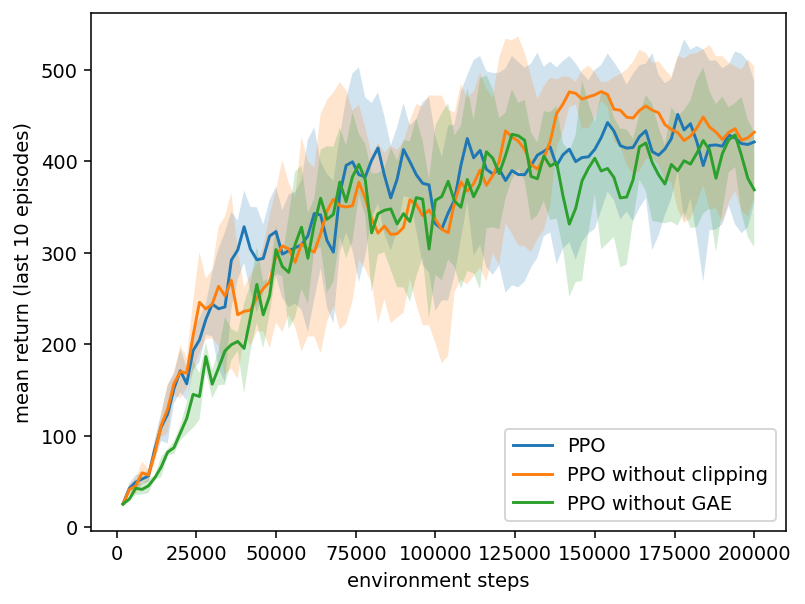

In [6]:
all_runs = {"PPO": run_seeds()}
all_runs["PPO without clipping"] = run_seeds({"clip_coef": 1e9})
all_runs["PPO without GAE"] = run_seeds({"gae_lambda": 1.0})
results = {name: summarize(runs, name) for name, runs in all_runs.items()}
plot_curves(all_runs)

# Bonus Research Question 2: your method

Write your method as a copy of `train_ppo` (and of the other functions that you change).
Use `run_seeds(train_fn=my_train_ppo)` and `summarize` for the results.

In [7]:
def my_train_ppo(seed, cfg=None, verbose=False, options=None):
    """PPO with time-limit bootstrapping and separate gradient clipping."""
    options = options or {}
    bootstrap_timeouts = options.get("bootstrap_timeouts", True)
    split_grad_clip = options.get("split_grad_clip", True)
    diagnostics = options.get("diagnostics")
    timeout_count = 0
    timeout_bonus_sum = 0.0
    actor_freed_count = 0
    minibatch_count = 0

    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4); actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N); rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v
            o, r, term, trunc, final_obs = envs.step(a.numpy())
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            timeouts = np.flatnonzero(trunc & ~term)
            timeout_count += len(timeouts)
            if bootstrap_timeouts and len(timeouts):
                # o contains the next episode's initial state at a timeout.
                # The TD target uses the final state of the episode that ended.
                final_states = torch.as_tensor(np.stack([final_obs[i] for i in timeouts]),
                                               dtype=torch.float32)
                with torch.no_grad():
                    timeout_bonus = cfg["gamma"] * agent.get_value(final_states)
                rewards[t, timeouts] += timeout_bonus
                timeout_bonus_sum += timeout_bonus.sum().item()
            # The original done mask still stops GAE at every episode boundary.
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        if split_grad_clip:
            stats = ppo_update_split_clip(agent, opt, b, cfg)
            actor_freed_count += stats["actor_freed_count"]
            minibatch_count += stats["minibatch_count"]
        else:
            stats = ppo_update(agent, opt, b, cfg)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  "
                  f"clip frac {stats['clip_frac']:.3f}")
    if diagnostics is not None:
        diagnostics.append({
            "seed": seed,
            "steps": envs.global_step,
            "timeouts": timeout_count,
            "timeout_bonus_sum": timeout_bonus_sum,
            "actor_freed_count": actor_freed_count,
            "minibatch_count": minibatch_count,
        })
    return agent, envs.episodes, time.time() - start


def ppo_update_split_clip(agent, opt, b, cfg):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    stats = []
    actor_freed_count = 0
    limit = cfg["max_grad_norm"]
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = torch.max(-adv * ratio,
                                -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            actor_norm = nn.utils.clip_grad_norm_(agent.actor.parameters(), limit).item()
            critic_norm = nn.utils.clip_grad_norm_(agent.critic.parameters(), limit).item()
            # Compare the clipping rule on these same pre-clipping gradients.
            if actor_norm <= limit < np.hypot(actor_norm, critic_norm):
                actor_freed_count += 1
            opt.step()
            stats.append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
    return {"clip_frac": float(np.mean(stats)),
            "actor_freed_count": actor_freed_count, "minibatch_count": len(stats)}


### Idea and ablations

The method changes two parts of PPO. Each addresses a different cause of potentially noisy updates.

1. **Bootstrap at time limits.** CartPole resets at 500 steps even if the pole is still balanced. Treat the cap as a cutoff when estimating training values. On a truncation without a true termination, use the target $r_t + \gamma V(s_{t+1}^{\rm final})$. The environment wrapper provides the observation just before reset. Add the bootstrap term to the reward tensor used by GAE and retain the done mask, so the advantage recursion stops at reset. The critic receives no continuation value after a true termination. This follows the partial-episode bootstrapping idea in [Pardo et al., *Time Limits in Reinforcement Learning*, ICML 2018, §3](https://proceedings.mlr.press/v80/pardo18a.html). The hypothesis is that avoiding an abrupt drop in the TD target at a successful timeout will help sustain performance once episodes get long. The benchmark still counts the actual reward up to 500 steps.
2. **Clip actor and critic gradients separately.** The starter uses two disjoint networks but computes one global gradient norm. A large value-loss gradient can reduce the actor's update even when the actor gradient is below the limit. Apply the same norm cap to each network separately. This lets each network use its own clipping factor. The combined post-clipping norm can be larger than with joint clipping, which is part of the change being tested.

The table compares the full method with the starter and with each one-component variant. All variants use the starter's CartPole-v1, configured 200,000 steps, seeds 0–4, and evaluation. The trainer collects 199,680 actual steps in 390 complete rollouts, as in the starter. The diagnostic for separate clipping counts minibatches in which the actor norm is within its own cap while the joint norm exceeds the cap, using the gradients observed in that run.

In [8]:
from functools import partial
from IPython.display import Markdown, display

bonus_diagnostics = {name: [] for name in ("Full method", "Timeout bootstrap only", "Separate clipping only")}
bonus_runs = {"PPO": all_runs["PPO"]}
bonus_runs["Full method"] = run_seeds(train_fn=partial(
    my_train_ppo, options={"diagnostics": bonus_diagnostics["Full method"]}))
bonus_runs["Timeout bootstrap only"] = run_seeds(train_fn=partial(
    my_train_ppo, options={"split_grad_clip": False, "diagnostics": bonus_diagnostics["Timeout bootstrap only"]}))
bonus_runs["Separate clipping only"] = run_seeds(train_fn=partial(
    my_train_ppo, options={"bootstrap_timeouts": False, "diagnostics": bonus_diagnostics["Separate clipping only"]}))


seed 0: auc  390.9  steps_to_475  72207  final  500.0  time  32.8 s
seed 1: auc  394.7  steps_to_475  65441  final  500.0  time  29.8 s
seed 2: auc  359.9  steps_to_475  60439  final  486.6  time  33.7 s
seed 3: auc  397.5  steps_to_475  55535  final  500.0  time  31.6 s
seed 4: auc  424.1  steps_to_475  62472  final  500.0  time  30.7 s
seed 0: auc  305.5  steps_to_475  87564  final  246.8  time  31.5 s
seed 1: auc  327.4  steps_to_475  61326  final  494.9  time  30.1 s
seed 2: auc  363.8  steps_to_475  57346  final  500.0  time  32.5 s
seed 3: auc  245.8  steps_to_475  79371  final  279.7  time  31.2 s
seed 4: auc  395.9  steps_to_475  76650  final  500.0  time  29.4 s
seed 0: auc  308.8  steps_to_475 100265  final  491.9  time  32.9 s
seed 1: auc  323.8  steps_to_475  46413  final  500.0  time  31.4 s
seed 2: auc  270.7  steps_to_475  77969  final  423.4  time  35.5 s
seed 3: auc  407.8  steps_to_475  50599  final  497.6  time  31.2 s
seed 4: auc  278.3  steps_to_475  63645  final  

PPO                      auc  342.0 +-  43.5  steps_to_475    95090 (5/5 runs)  final  471.8 +-  55.7  time  30.2 s
Full method              auc  393.4 +-  20.4  steps_to_475    63219 (5/5 runs)  final  497.3 +-   5.4  time  31.7 s
Timeout bootstrap only   auc  327.7 +-  51.3  steps_to_475    72451 (5/5 runs)  final  404.3 +- 115.6  time  31.0 s
Separate clipping only   auc  317.9 +-  49.0  steps_to_475    67778 (5/5 runs)  final  458.4 +-  48.8  time  32.2 s


| Variant | AUC (mean ± SD) | Steps to 475 | Reached 475 | Final greedy return (mean ± SD) |
|---|---:|---:|---:|---:|
| PPO | 341.96 ± 43.50 | 95,090 | 5/5 | 471.82 ± 55.66 |
| Full method | 393.40 ± 20.44 | 63,219 | 5/5 | 497.31 ± 5.38 |
| Timeout bootstrap only | 327.67 ± 51.29 | 72,451 | 5/5 | 404.26 ± 115.64 |
| Separate clipping only | 317.88 ± 48.96 | 67,778 | 5/5 | 458.38 ± 48.81 |

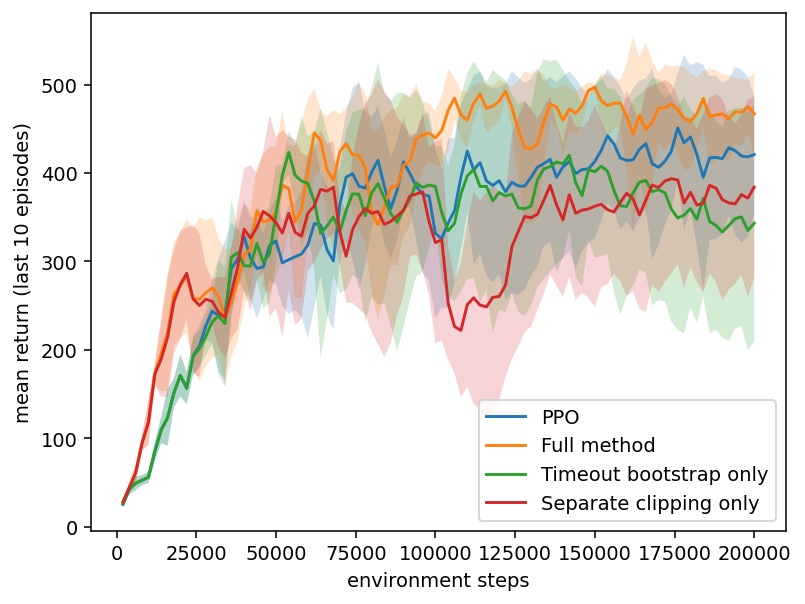

Full method: 1202 pure timeouts across all five seeds
  Mean added value at a timeout: 53.43
  Actor within its own cap while joint norm exceeds cap: 94.5% of minibatches
Timeout bootstrap only: 745 pure timeouts across all five seeds
  Mean added value at a timeout: 51.83
Separate clipping only: 627 pure timeouts across all five seeds
  Actor within its own cap while joint norm exceeds cap: 89.5% of minibatches


In [9]:
bonus_results = {name: summarize(runs, name) for name, runs in bonus_runs.items()}
table = [
    "| Variant | AUC (mean ± SD) | Steps to 475 | Reached 475 | Final greedy return (mean ± SD) |",
    "|---|---:|---:|---:|---:|",
]
for name, row in bonus_results.items():
    table.append(f"| {name} | {row['auc']:.2f} ± {row['auc_std']:.2f} | "
                 f"{row['steps_to_475']:,.0f} | {row['solved']}/{len(SEEDS)} | "
                 f"{row['final']:.2f} ± {row['final_std']:.2f} |")
display(Markdown("\n".join(table)))
plot_curves(bonus_runs)

for name, rows in bonus_diagnostics.items():
    timeouts = sum(row["timeouts"] for row in rows)
    print(f"{name}: {timeouts} pure timeouts across all five seeds")
    if name != "Separate clipping only" and timeouts:
        bonus = sum(row["timeout_bonus_sum"] for row in rows) / timeouts
        print(f"  Mean added value at a timeout: {bonus:.2f}")
    updates = sum(row["minibatch_count"] for row in rows)
    if updates:
        freed = sum(row["actor_freed_count"] for row in rows)
        print(f"  Actor within its own cap while joint norm exceeds cap: {freed / updates:.1%} of minibatches")


### Results and analysis

The full method increased mean AUC from **341.96 to 393.40** (+15.0%) and reduced mean steps to a rolling return of 475 from **95,090 to 63,219** (−33.5%). Its final greedy evaluation averaged **497.31**, compared with **471.82** for PPO. It improved AUC on four of five paired seeds. Seed 2 was the exception, with 359.89 for the full method and 375.39 for PPO.

The curves show a higher and steadier late training return with both changes. Over the last 25 evaluation points of the training curve (152,000–200,000 steps), the mean return was 468.06 for the full method and 422.67 for PPO. Computing the standard deviation over those points within each seed and then averaging over seeds gives 19.48 for the full method and 27.77 for PPO. The final greedy evaluation also varied less across the five seeds (SD 5.38 versus 55.66). These metrics summarize different behavior because the curve uses sampled actions during training and the final evaluation uses greedy actions.

**Ablations.** Removing separate gradient clipping while keeping timeout bootstrapping dropped AUC from 393.40 to 327.67 and final greedy return from 497.31 to 404.26. Removing timeout bootstrapping while keeping separate clipping dropped AUC to 317.88 and final greedy return to 458.38. Both single-change variants first reached 475 sooner than starter PPO on average, yet each had a lower AUC and a lower late training mean. A first crossing can occur during a short period of high returns. In this experiment the combined changes also helped the policy sustain higher returns.

**What the diagnostics show.** In the full method, 1,202 training episodes ended at a pure timeout, and the average added value at those transitions was 53.43. This changes the critic target appreciably when a long episode hits the cap. The full method also had an actor gradient within its own cap and a joint norm above the cap in 94.5% of minibatches. For those same gradients, joint clipping would shrink the actor gradient while separate clipping leaves it at its original size. The split-only variant met that condition in 89.5% of minibatches but had lower AUC than PPO. Preserving the actor gradient alone therefore did not improve overall learning here. The ablations support the benefit of using both changes together in this setting. The gradient diagnostic compares clipping rules on observed gradients, so it does not establish a causal explanation for later policy behavior. Five paired seeds on CartPole support a conclusion about this experiment.

**Reproduction.** The five starter PPO runs come from part (a), and all 15 bonus runs use the same seeds and runtime (PyTorch 2.5.1+cpu, Gymnasium 1.4.0, NumPy 2.3.5). The notebook uses the starter's `run_seeds`, `summarize`, and `plot_curves`. Disabling both changes reproduced the starter's seed-0 episode trace and final greedy return exactly in this runtime.